# House Prices Prediction

Machine Learning, Practical Work 1

Dataset: [Kaggle House Prices, Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Ames housing, 1460 labelled rows, 79 features.

Map to PW1:
- Task 1, data exploration and preprocessing: sections 1 to 7
- Task 2, feature engineering: sections 6 and 8
- Task 3, model training and evaluation, MAE, RMSE, R2: sections 9 to 11
- Task 4, hyperparameter tuning: section 10
- Bonus, Ridge/Lasso/ElasticNet in section 9, stacking ensemble in section 12, Streamlit app in section 14.

## 1. Setup and imports

In [1]:
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, probplot, loguniform, uniform, randint

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
)
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import (
    train_test_split, KFold, cross_validate, RandomizedSearchCV,
    validation_curve, learning_curve
)
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error
)
from sklearn.inspection import permutation_importance
from sklearn import set_config

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

from IPython.display import display

RANDOM_STATE = 42
TARGET = "SalePrice"

pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "figure.autolayout": True,
})
set_config(display="diagram")

print(f"pandas {pd.__version__} | scikit-learn {__import__('sklearn').__version__} | xgboost {xgb.__version__ if HAS_XGB else 'not installed'}")

pandas 2.3.3 | scikit-learn 1.6.1 | xgboost 3.4.1


## 2. Load the data


In [2]:
from pathlib import Path

KAGGLE_DIR = Path("/kaggle/input/competitions/house-prices-advanced-regression-techniques")
KAGGLE_INPUT = Path("/kaggle/input")
LOCAL_DIRS = [Path("."), Path("data"), Path("archive/data")]

def find_csv(name):
    candidates = [KAGGLE_DIR / name] + [d / name for d in LOCAL_DIRS]
    for path in candidates:
        if path.exists():
            return path
    # Fallback: search the whole /kaggle/input tree in case the layout differs
    if KAGGLE_INPUT.exists():
        matches = sorted(KAGGLE_INPUT.rglob(name))
        if matches:
            return matches[0]
    raise FileNotFoundError(
        f"{name} not found. On Kaggle attach the competition "
        "'House Prices - Advanced Regression Techniques' "
        "(Add data -> Competitions). "
        "Locally put the CSVs in the working directory, in ./data or in ./archive/data."
    )

df_raw = pd.read_csv(find_csv("train.csv"))
df_test_raw = pd.read_csv(find_csv("test.csv"))

print(f"Train: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(f"Test : {df_test_raw.shape[0]} rows x {df_test_raw.shape[1]} columns")


Train: 1460 rows x 81 columns
Test : 1459 rows x 80 columns


## 3. Basic statistics

In [3]:
display(df_raw.head())
print(df_raw.dtypes.value_counts().to_string())
print("\nSummary statistics of the numerical variables:")
display(df_raw.describe().T.round(2))
print("Target variable:")
print(df_raw[TARGET].describe().round(1).to_string())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


object     43
int64      35
float64     3

Summary statistics of the numerical variables:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


Target variable:
count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0


## 4. Missing values

Most `NaN` in this dataset mean "the house does not have this feature", not "unknown". Strategy:
- Features absent: fill with `"None"` (example: `PoolQC = NaN` means no pool)
- Area or count absent: fill with `0` (example: `GarageArea = NaN` means no garage)
- `LotFrontage`: real missing values, imputed by the median of the same neighborhood inside the pipeline
- `Electrical`: a single missing row, imputed by the most frequent value inside the pipeline

19 columns contain missing values


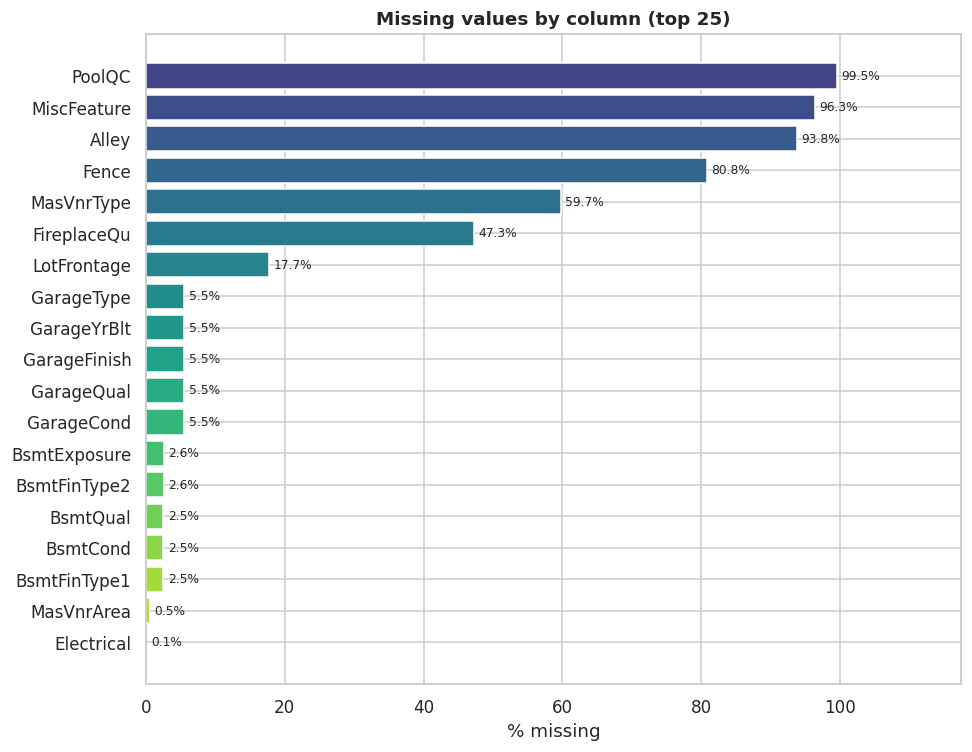

In [4]:
missing = pd.DataFrame({
    "missing": df_raw.isna().sum(),
    "percent": 100 * df_raw.isna().mean(),
})
missing = missing[missing["missing"] > 0].sort_values("percent", ascending=False)

print(f"{len(missing)} columns contain missing values")

fig, ax = plt.subplots(figsize=(9, 7))
top = missing.head(25)[::-1]
bars = ax.barh(top.index, top["percent"], color=plt.cm.viridis(np.linspace(0.95, 0.2, len(top))))
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xlabel("% missing")
ax.set_title("Missing values by column (top 25)")
ax.set_xlim(0, top["percent"].max() * 1.18)
plt.show()

In [5]:
NA_MEANS_NONE = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]
NA_MEANS_ZERO = [
    "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath",
]

def fill_semantic_na(dataframe):
    df = dataframe.copy()
    for col in NA_MEANS_NONE:
        if col in df.columns:
            df[col] = df[col].fillna("None")
    for col in NA_MEANS_ZERO:
        if col in df.columns:
            df[col] = df[col].fillna(0)
    return df

df = fill_semantic_na(df_raw).drop(columns=["Id"])
remaining = df.isna().sum()
print(remaining[remaining > 0].to_string())
print("LotFrontage and Electrical are imputed inside the pipeline (no leakage).")

LotFrontage    259
Electrical       1
LotFrontage and Electrical are imputed inside the pipeline (no leakage).


## 5. Exploratory data analysis

SalePrice is right-skewed, so we train on `log1p(SalePrice)` and convert predictions back to dollars with `TransformedTargetRegressor`.

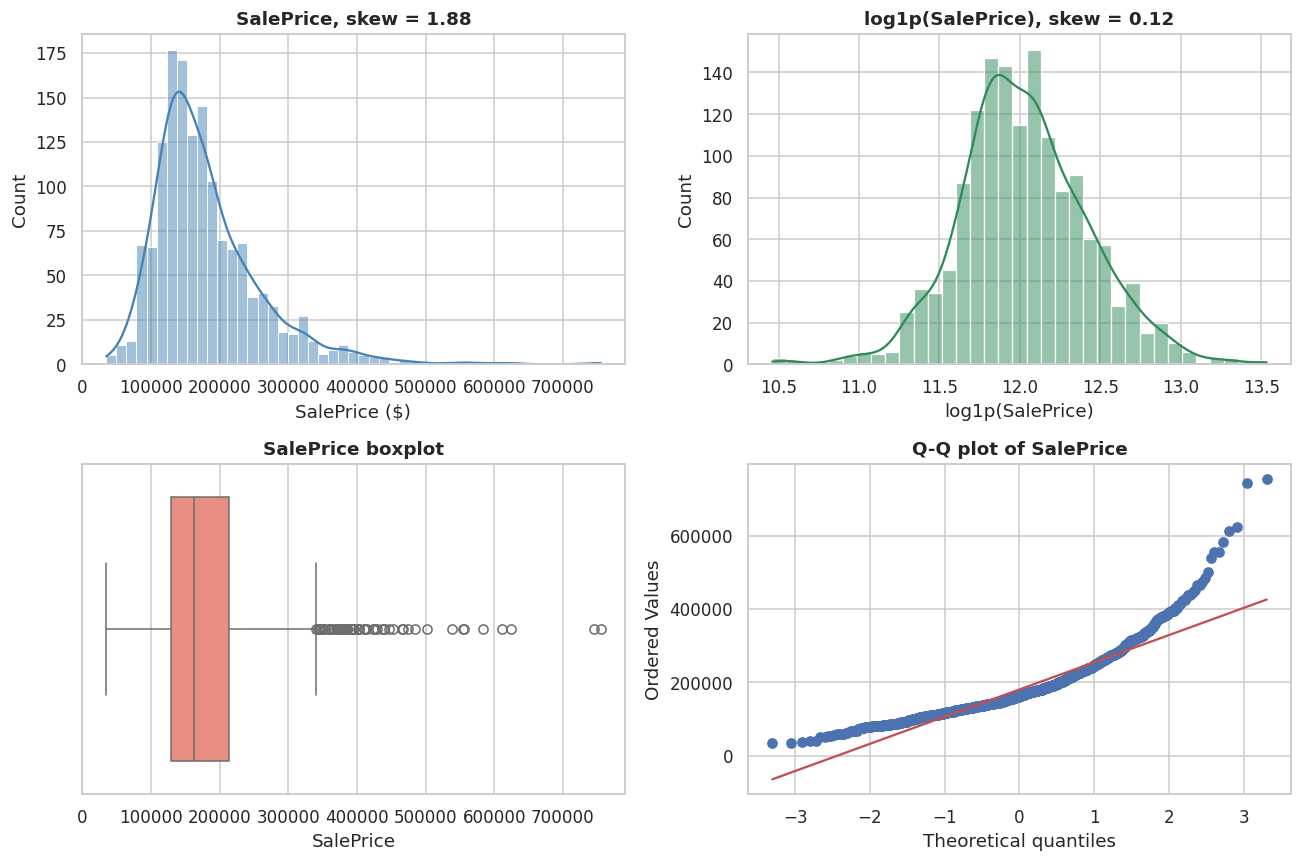

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df[TARGET], kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title(f"SalePrice, skew = {df[TARGET].skew():.2f}")
axes[0, 0].set_xlabel("SalePrice ($)")

sns.histplot(np.log1p(df[TARGET]), kde=True, ax=axes[0, 1], color="seagreen")
axes[0, 1].set_title(f"log1p(SalePrice), skew = {np.log1p(df[TARGET]).skew():.2f}")
axes[0, 1].set_xlabel("log1p(SalePrice)")

sns.boxplot(x=df[TARGET], ax=axes[1, 0], color="salmon")
axes[1, 0].set_title("SalePrice boxplot")

probplot(df[TARGET], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot of SalePrice")

plt.show()

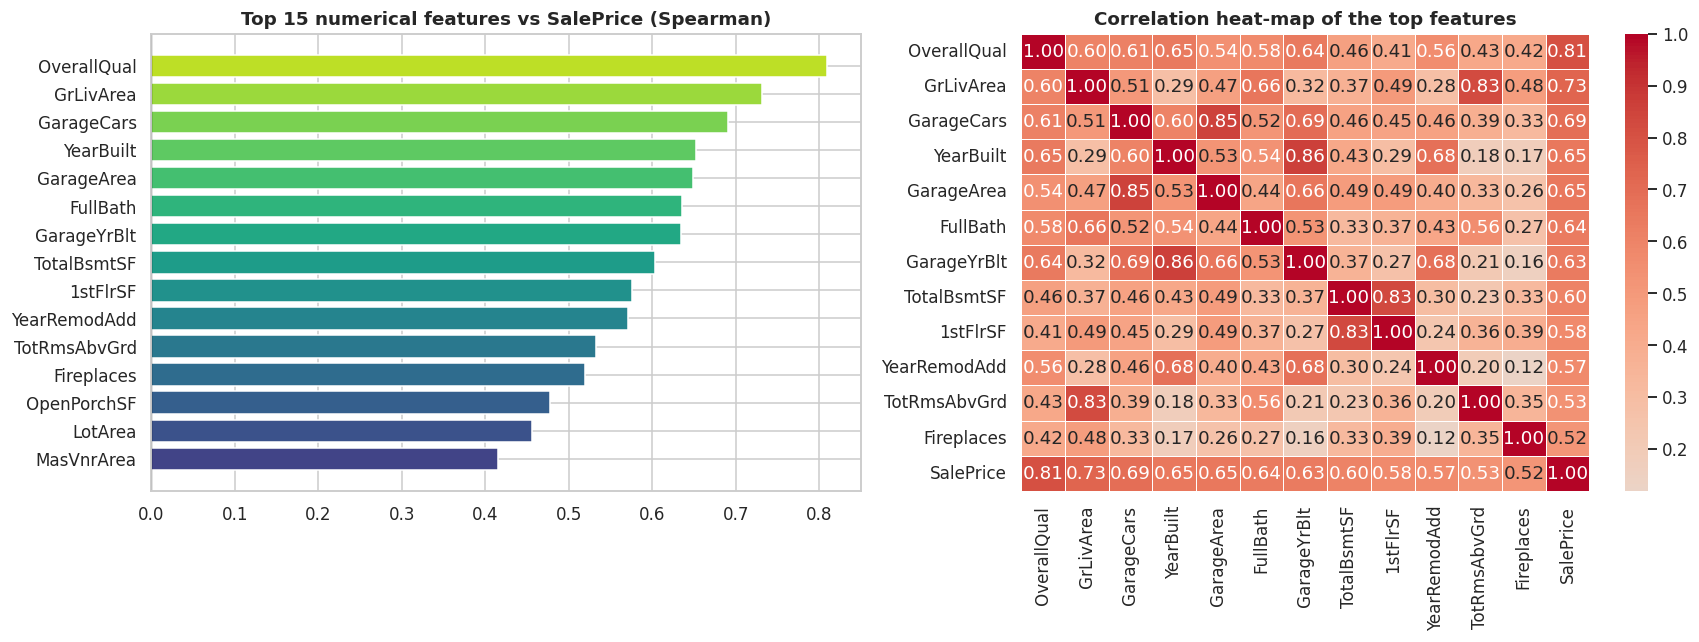

In [7]:
num_cols = df.select_dtypes(include=np.number).drop(columns=[TARGET]).columns
corr_target = (
    df[list(num_cols) + [TARGET]]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(key=np.abs, ascending=False)
)
top15 = corr_target.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top15.index[::-1], top15.values[::-1],
             color=plt.cm.viridis(np.linspace(0.2, 0.9, len(top15))))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Top 15 numerical features vs SalePrice (Spearman)")

heat_cols = top15.head(12).index.tolist() + [TARGET]
sns.heatmap(df[heat_cols].corr(method="spearman"), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", linewidths=0.4, ax=axes[1])
axes[1].set_title("Correlation heat-map of the top features")
plt.show()

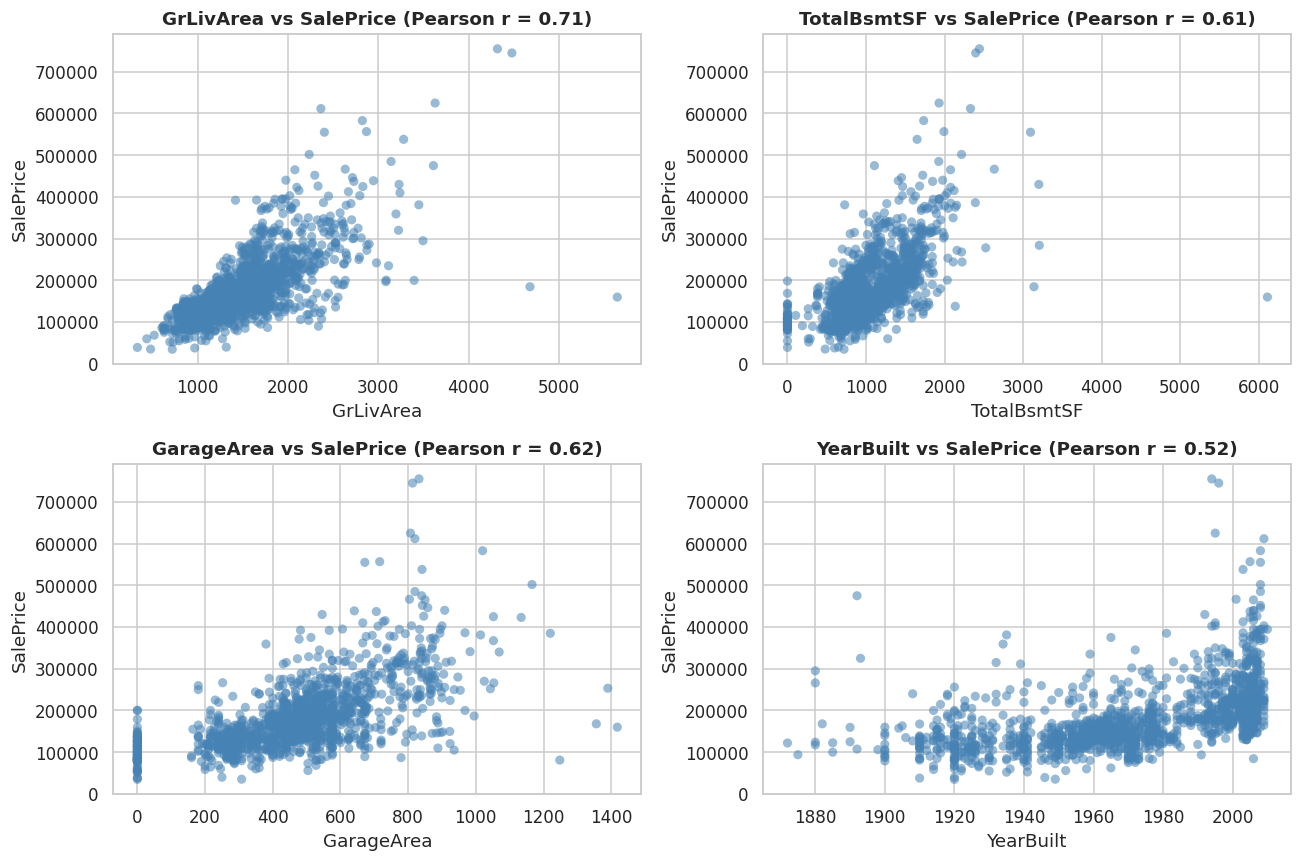

In [8]:
features = ["GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.ravel(), features):
    sns.scatterplot(data=df, x=col, y=TARGET, ax=ax, alpha=0.55,
                    edgecolor="none", color="steelblue")
    r = df[[col, TARGET]].corr().iloc[0, 1]
    ax.set_title(f"{col} vs SalePrice (Pearson r = {r:.2f})")
plt.show()

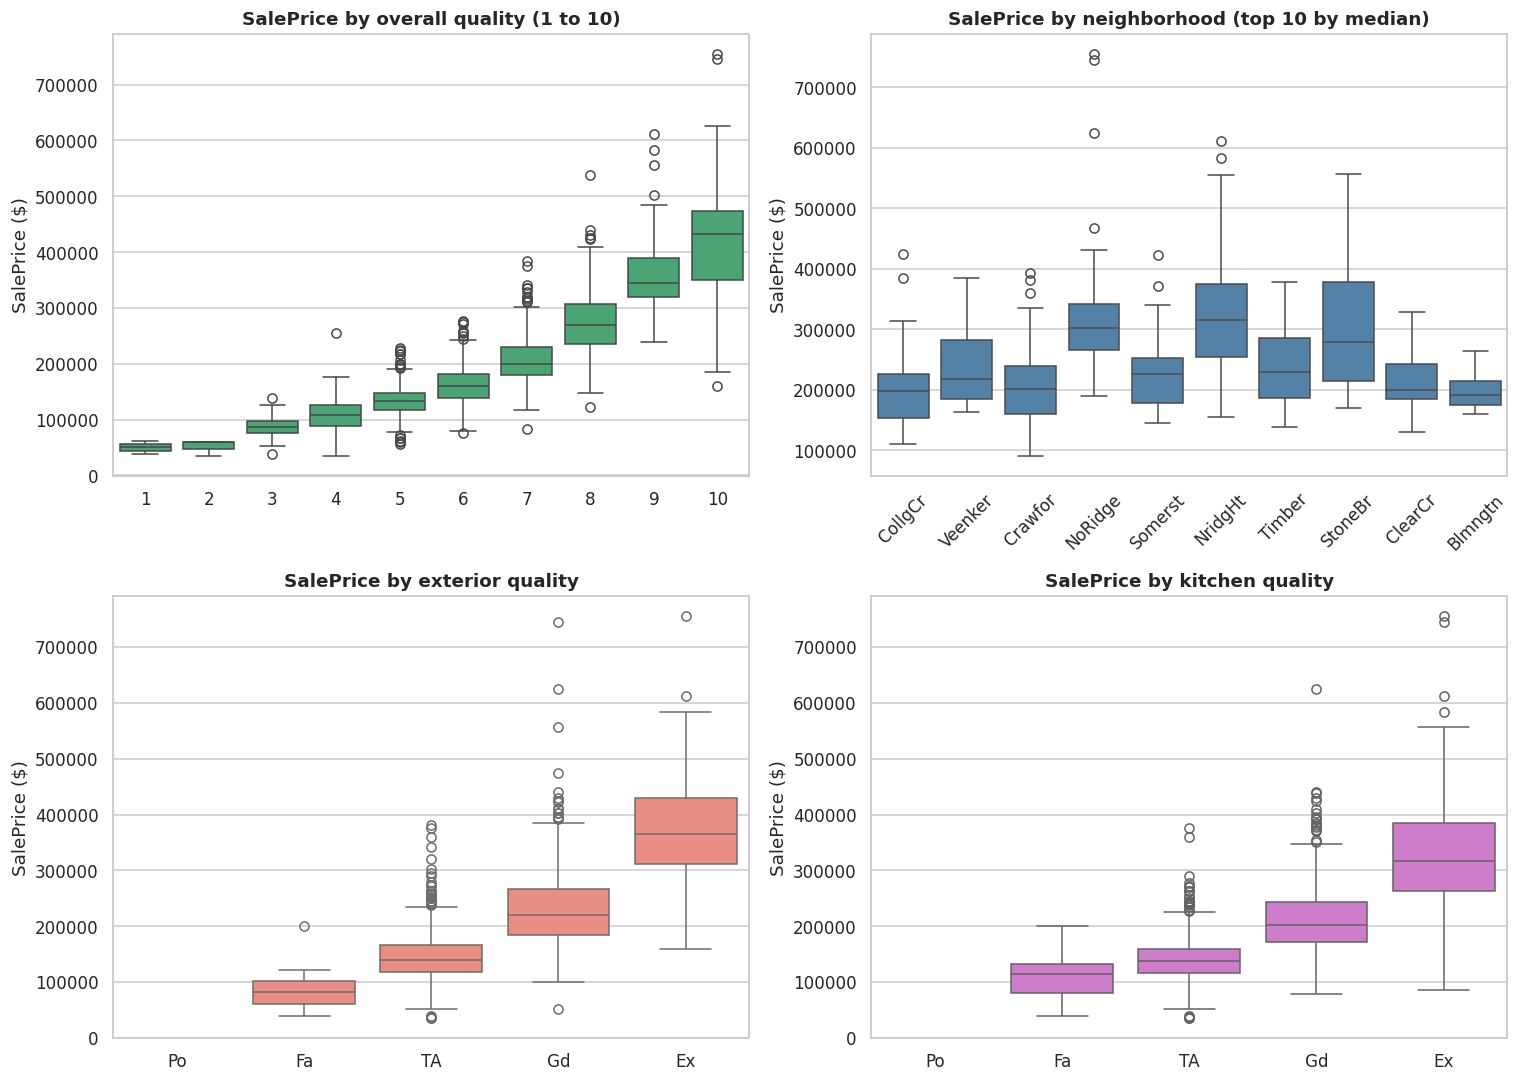

In [9]:
top_neigh = (df.groupby("Neighborhood")[TARGET]
               .median().sort_values(ascending=False).head(10).index)
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="OverallQual", y=TARGET, ax=axes[0, 0], color="mediumseagreen")
axes[0, 0].set_title("SalePrice by overall quality (1 to 10)")

sns.boxplot(data=df[df["Neighborhood"].isin(top_neigh)],
            x="Neighborhood", y=TARGET, ax=axes[0, 1], color="steelblue")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].set_title("SalePrice by neighborhood (top 10 by median)")

sns.boxplot(data=df, x="ExterQual", y=TARGET, order=quality_order,
            ax=axes[1, 0], color="salmon")
axes[1, 0].set_title("SalePrice by exterior quality")

sns.boxplot(data=df, x="KitchenQual", y=TARGET, order=quality_order,
            ax=axes[1, 1], color="orchid")
axes[1, 1].set_title("SalePrice by kitchen quality")

for ax in axes.ravel():
    ax.set_ylabel("SalePrice ($)")
    ax.set_xlabel("")
plt.show()

## 6. Feature engineering

New features:
- `TotalSF`: basement + 1st floor + 2nd floor
- `TotalBath`: full baths + half baths (x0.5), including basement
- `TotalPorchSF`: all porch surfaces
- `HouseAge`, `RemodAge`, `IsRemodeled`: age and renovation recency
- `HasPool`, `HasGarage`, `HasBasement`, `Has2ndFloor`: amenity flags
- `OverallGrade`: OverallQual x OverallCond
- `QualxSF`: OverallQual x TotalSF
- `LivAreaPerRoom`: GrLivArea per room
- `GarageScore`: GarageArea x GarageCars

Quality ratings are encoded as ordered numbers (`None=0 ... Ex=5`). Nominal codes such as `MSSubClass` are treated as strings.

In [10]:
QUALITY = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

ORDINAL_MAPS = {
    "ExterQual": QUALITY, "ExterCond": QUALITY, "BsmtQual": QUALITY,
    "BsmtCond": QUALITY, "HeatingQC": QUALITY, "KitchenQual": QUALITY,
    "FireplaceQu": QUALITY, "GarageQual": QUALITY, "GarageCond": QUALITY,
    "PoolQC": QUALITY,
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3,
                   "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "CentralAir": {"N": 0, "Y": 1},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "LandSlope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "LotShape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Street": {"Grvl": 0, "Pave": 1},
    "Alley": {"None": 0, "Grvl": 1, "Pave": 2},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
}

def engineer_features(dataframe):
    df = dataframe.copy()

    if "MSSubClass" in df.columns:
        df["MSSubClass"] = df["MSSubClass"].astype(str)

    for col, mapping in ORDINAL_MAPS.items():
        if col in df.columns:
            df[col] = df[col].map(mapping)

    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalBath"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                       + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])
    df["TotalPorchSF"] = (df["OpenPorchSF"] + df["EnclosedPorch"]
                          + df["3SsnPorch"] + df["ScreenPorch"])
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
    df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)

    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    df["HasBasement"] = (df["TotalBsmtSF"] > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)

    df["OverallGrade"] = df["OverallQual"] * df["OverallCond"]
    df["QualxSF"] = df["OverallQual"] * df["TotalSF"]
    df["LivAreaPerRoom"] = df["GrLivArea"] / df["TotRmsAbvGrd"].clip(lower=1)
    df["GarageScore"] = df["GarageArea"] * df["GarageCars"]

    df = df.drop(columns=[c for c in ["Id", "Utilities"] if c in df.columns])
    return df

engineered = [
    "TotalSF", "TotalBath", "TotalPorchSF", "HouseAge", "RemodAge", "IsRemodeled",
    "HasPool", "HasGarage", "HasBasement", "Has2ndFloor", "OverallGrade",
    "QualxSF", "LivAreaPerRoom", "GarageScore",
]

df_model = engineer_features(df)
print(f"Shape before engineering: {df.shape}")
print(f"Shape after engineering : {df_model.shape}")
print(f"{len(engineered)} new features created")

Shape before engineering: (1460, 80)
Shape after engineering : (1460, 93)
14 new features created


Two houses have more than 4000 sq ft above ground but sold for less than 300k. These are known partial sales of the Ames dataset. They are removed from the labelled data only.

Note: the rule uses the target (`SalePrice`) to choose which rows to drop. This is an accepted convention for this specific dataset (the two sales are not representative of full market value), and it does not leak target information into any feature or statistic ; the same two rows are removed before the split, so train and hold-out are treated identically.

In [11]:
outliers = df_model[(df_model["GrLivArea"] > 4000) & (df_model[TARGET] < 300000)]
print(f"{len(outliers)} extreme outlier(s) identified")
display(outliers[["GrLivArea", "TotalSF", "OverallQual", "SalePrice"]])

before = len(df_model)
df_model = df_model.drop(index=outliers.index).reset_index(drop=True)
print(f"Rows kept: {len(df_model)} / {before}")

2 extreme outlier(s) identified


,GrLivArea,TotalSF,OverallQual,SalePrice
523,4676,7814,10,184750
1298,5642,11752,10,160000


Rows kept: 1458 / 1460


Train/test split before any statistics. 80% train for cross-validation and tuning, 20% hold-out, touched once at the end.

In [12]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape}")
print(f"X_test : {X_test.shape}")

X_train: (1166, 92)
X_test : (292, 92)


Long-tailed numerical features are log1p-transformed. The list of skewed features is learned on the training set only.

In [13]:
ordinal_cols = list(ORDINAL_MAPS.keys())
numeric_candidates = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c not in ordinal_cols
]

skewness = X_train[numeric_candidates].apply(lambda s: s.skew())
SKEWED_FEATURES = skewness[skewness.abs() > 0.75].sort_values(ascending=False).index.tolist()
print(f"{len(SKEWED_FEATURES)} skewed features will be log1p-transformed")

def log_transform(dataframe, columns):
    df = dataframe.copy()
    for col in columns:
        if col in df.columns:
            df[col] = np.log1p(df[col].clip(lower=0))
    return df

X_train = log_transform(X_train, SKEWED_FEATURES)
X_test = log_transform(X_test, SKEWED_FEATURES)

27 skewed features will be log1p-transformed


## 7. Preprocessing pipeline and scaling

All preprocessing lives inside a scikit-learn `Pipeline`/`ColumnTransformer`, fitted on training folds only:
- Numerical features: median imputation, then `StandardScaler`
- Categorical features: most-frequent imputation, then one-hot encoding (`handle_unknown="ignore"`)
- `LotFrontage`: custom transformer, fills with the neighborhood median learned on training data
- Target: `log1p` before fitting, `expm1` after prediction

In [14]:
NUM_FEATURES = X_train.select_dtypes(include=np.number).columns.tolist()
CAT_FEATURES = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"{len(NUM_FEATURES)} numerical features | {len(CAT_FEATURES)} categorical features")

class LotFrontageImputer(BaseEstimator, TransformerMixin):
    def __init__(self, col="LotFrontage", group_col="Neighborhood"):
        self.col = col
        self.group_col = group_col

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        if self.col in X.columns and self.group_col in X.columns:
            self.global_median_ = X[self.col].median()
            self.group_medians_ = X.groupby(self.group_col)[self.col].median()
        else:
            self.global_median_ = None
            self.group_medians_ = None
        return self

    def transform(self, X):
        X = X.copy()
        if self.col in X.columns and self.group_medians_ is not None:
            fill_values = X[self.group_col].map(self.group_medians_).fillna(self.global_median_)
            X[self.col] = X[self.col].fillna(fill_values)
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = getattr(self, "feature_names_in_", None)
        return np.asarray(input_features, dtype=object)

def build_preprocessor(num_features, cat_features, lotfrontage=True):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore",
                                 sparse_output=False,
                                 min_frequency=3)),
    ])
    columns = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, num_features),
            ("cat", categorical_pipe, cat_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline([
        *([("lotfrontage", LotFrontageImputer())] if lotfrontage else []),
        ("columns", columns),
    ])

preprocessor = build_preprocessor(NUM_FEATURES, CAT_FEATURES)
X_train_prepared = preprocessor.fit_transform(X_train)

print(f"Raw matrix      : {X_train.shape}")
print(f"Prepared matrix : {X_train_prepared.shape}")
print(f"Any remaining NaN: {np.isnan(X_train_prepared).any()}")

71 numerical features | 21 categorical features
Raw matrix      : (1166, 92)
Prepared matrix : (1166, 231)
Any remaining NaN: False


## 8. Feature relevance and selection

Two views: Spearman correlation with the target, and Random Forest importance. Then we test empirically if keeping only the median-importance features helps, inside cross-validation.

,Spearman correlation
QualxSF,0.890
TotalSF,0.816
OverallQual,0.801
GrLivArea,0.729
TotalBath,0.702
GarageCars,0.694
GarageScore,0.675
KitchenQual,0.672
ExterQual,0.671
BsmtQual,0.667


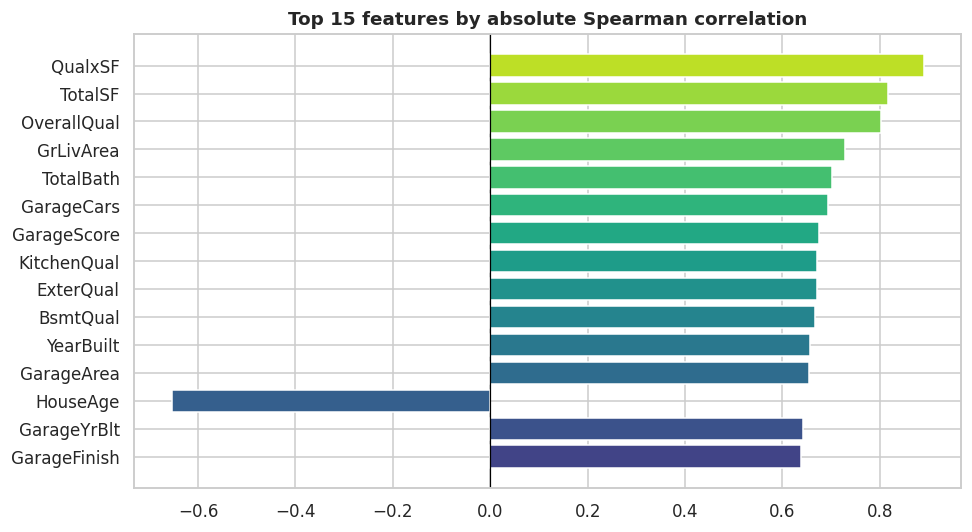

In [15]:
corr_with_target = (
    X_train[NUM_FEATURES]
    .apply(lambda col: col.corr(y_train, method="spearman"))
    .sort_values(key=np.abs, ascending=False)
)
display(corr_with_target.head(15).round(3).to_frame("Spearman correlation"))

fig, ax = plt.subplots(figsize=(9, 5))
top = corr_with_target.head(15)[::-1]
ax.barh(top.index, top.values, color=plt.cm.viridis(np.linspace(0.2, 0.9, len(top))))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Top 15 features by absolute Spearman correlation")
plt.show()

In [ ]:
feature_names = preprocessor.get_feature_names_out()

rf_importance = RandomForestRegressor(
    n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train_prepared, y_train)

importances = (pd.Series(rf_importance.feature_importances_, index=feature_names)
               .sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, series, title in [
    (axes[0], importances.head(15), "Top 15 features, QualxSF dominates"),
    (axes[1], importances.drop(index=["QualxSF"], errors="ignore").head(15),
     "Without QualxSF"),
]:
    top = series[::-1]
    ax.barh(top.index, top.values,
            color=plt.cm.magma(np.linspace(0.85, 0.25, len(top))))
    ax.set_title(title)
    ax.set_xlabel("Mean decrease in impurity")
    ax.tick_params(axis="y", labelsize=9)
plt.show()

In [ ]:
def wrap_target(model):
    return TransformedTargetRegressor(
        regressor=model, func=np.log1p, inverse_func=np.expm1, check_inverse=False
    )

def make_ttr(estimator):
    pipe = Pipeline([
        ("prep", build_preprocessor(NUM_FEATURES, CAT_FEATURES)),
        ("model", estimator),
    ])
    return wrap_target(pipe)

rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

all_features_model = make_ttr(clone(rf))
selected_features_model = make_ttr(Pipeline([
    ("select", SelectFromModel(
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        threshold="median")),
    ("rf", clone(rf)),
]))

for label, model in {"All features": all_features_model,
                     "Median-important features": selected_features_model}.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=1)
    print(f"{label:<30s} CV RMSE = ${-scores['test_score'].mean():,.0f}")

## 9. Model training and comparison

Models compared (5-fold CV on the training set, then hold-out evaluation once):
- Linear Regression (baseline)
- Ridge, Lasso, ElasticNet (regularized linear)
- KNN
- Random Forest
- Gradient Boosting
- XGBoost

----> All metrics are in dollars and percentage.

In [18]:
def regression_metrics(y_true, y_pred):
    mean_actual = float(np.mean(y_true))
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        "MAE": mae,
        "MAE %": mae / mean_actual,
        "RMSE": rmse,
        "RMSE %": rmse / mean_actual,
        "R2": r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "RMSLE": np.sqrt(mean_squared_error(
            np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None)))),
    }

def build_models():
    models = {
        "Linear Regression": LinearRegression(),
        "Ridge": Ridge(alpha=10.0),
        "Lasso": Lasso(alpha=5e-4, max_iter=10_000, tol=1e-3),
        "ElasticNet": ElasticNet(alpha=5e-4, l1_ratio=0.5, max_iter=10_000, tol=1e-3),
        "KNN": KNeighborsRegressor(n_neighbors=7, weights="distance"),
        "Random Forest": RandomForestRegressor(
            n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=400, learning_rate=0.05, max_depth=3,
            random_state=RANDOM_STATE),
    }
    if HAS_XGB:
        models["XGBoost"] = xgb.XGBRegressor(
            n_estimators=400, learning_rate=0.05, max_depth=3,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
            verbosity=0)
    return models

models = build_models()
fitted_models = {}
rows = []

for name, estimator in models.items():
    start = time.time()
    model = make_ttr(clone(estimator))

    cv_scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"MAE": "neg_mean_absolute_error",
                 "RMSE": "neg_root_mean_squared_error",
                 "R2": "r2"},
        n_jobs=1,
    )

    model.fit(X_train, y_train)
    fitted_models[name] = model
    holdout = regression_metrics(y_test, model.predict(X_test))

    target_mean = float(y.mean())
    rows.append({
        "Model": name,
        "CV RMSE": -cv_scores["test_RMSE"].mean(),
        "CV RMSE %": -cv_scores["test_RMSE"].mean() / target_mean,
        "CV RMSE std": cv_scores["test_RMSE"].std(),
        "CV MAE": -cv_scores["test_MAE"].mean(),
        "CV R2": cv_scores["test_R2"].mean(),
        "Hold-out RMSE": holdout["RMSE"],
        "Hold-out RMSE %": holdout["RMSE"] / target_mean,
        "Hold-out MAE": holdout["MAE"],
        "Hold-out MAE %": holdout["MAE"] / target_mean,
        "Hold-out R2": holdout["R2"],
        "Hold-out MAPE": holdout["MAPE"],
        "Fit time (s)": time.time() - start,
    })
    print(f"[done] {name:<20s} CV RMSE = ${rows[-1]['CV RMSE']:,.0f}")

results = pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE")
display(results.round(3))

[done] Random Forest        CV RMSE = $26,520
[done] Gradient Boosting    CV RMSE = $23,861
[done] XGBoost              CV RMSE = $23,565


,CV RMSE,CV RMSE %,CV RMSE std,CV MAE,CV R2,Hold-out RMSE,Hold-out RMSE %,Hold-out MAE,Hold-out MAE %,Hold-out R2,Hold-out MAPE,Fit time (s)
Model,,,,,,,,,,,,
ElasticNet,21496.762,0.119,2099.614,13982.354,0.927,18706.638,0.103,13462.223,0.074,0.937,0.080,1.073
Lasso,21608.833,0.119,2042.818,13981.864,0.927,18469.139,0.102,13447.848,0.074,0.938,0.080,0.802
Ridge,21853.471,0.121,2110.275,14077.126,0.925,18743.032,0.104,13456.686,0.074,0.936,0.081,0.838
Linear Regression,21965.922,0.121,1741.124,14479.423,0.924,20818.825,0.115,14365.240,0.079,0.922,0.086,0.737
XGBoost,23564.545,0.130,3213.524,14382.130,0.914,20006.517,0.111,14191.877,0.078,0.928,0.084,3.161
Gradient Boosting,23861.262,0.132,2746.516,14714.658,0.911,20192.609,0.112,14367.725,0.079,0.926,0.087,25.170
Random Forest,26520.032,0.147,3142.688,16989.945,0.890,24587.461,0.136,16298.568,0.090,0.891,0.100,29.528
KNN,35520.090,0.196,5312.395,20681.812,0.804,30006.047,0.166,20816.920,0.115,0.837,0.124,0.478


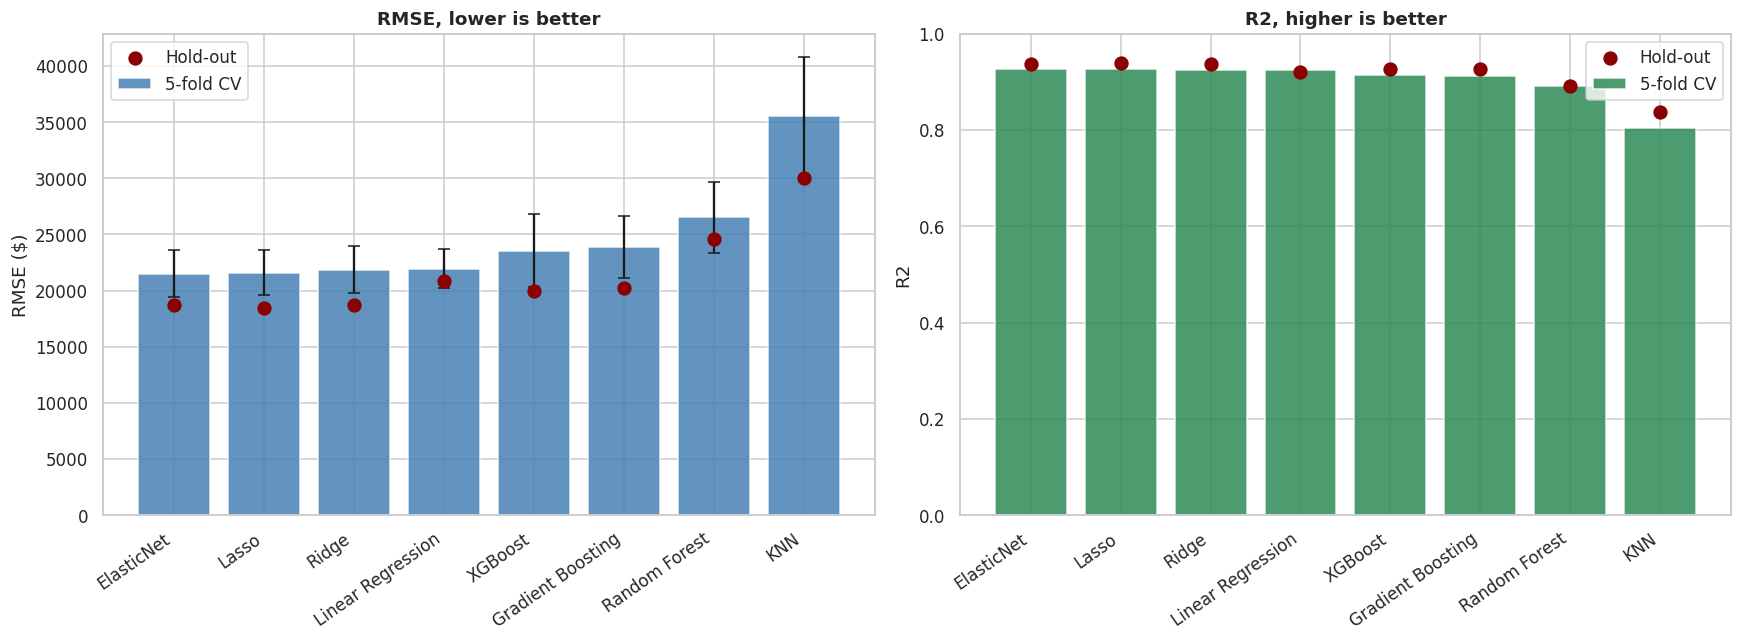

Best model by cross-validation: ElasticNet
RMSE improvement over Linear Regression: 2.1%


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
order = results.index
x = np.arange(len(order))

axes[0].bar(x, results["CV RMSE"], yerr=results["CV RMSE std"], capsize=4,
            color="steelblue", alpha=0.85, label="5-fold CV")
axes[0].scatter(x, results["Hold-out RMSE"], color="darkred", s=70, zorder=3,
                label="Hold-out")
axes[0].set_xticks(x)
axes[0].set_xticklabels(order, rotation=35, ha="right")
axes[0].set_ylabel("RMSE ($)")
axes[0].set_title("RMSE, lower is better")
axes[0].legend()

axes[1].bar(x, results["CV R2"], color="seagreen", alpha=0.85, label="5-fold CV")
axes[1].scatter(x, results["Hold-out R2"], color="darkred", s=70, zorder=3,
                label="Hold-out")
axes[1].set_xticks(x)
axes[1].set_xticklabels(order, rotation=35, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("R2")
axes[1].set_title("R2, higher is better")
axes[1].legend()
plt.show()

BEST_MODEL_NAME = results.index[0]
print(f"Best model by cross-validation: {BEST_MODEL_NAME}")
improvement = 100 * (results.loc["Linear Regression", "CV RMSE"] - results.loc[BEST_MODEL_NAME, "CV RMSE"]) / results.loc["Linear Regression", "CV RMSE"]
print(f"RMSE improvement over Linear Regression: {improvement:.1f}%")

## 10. Hyperparameter tuning

The best model is tuned with `RandomizedSearchCV` (up to 25 sampled configurations x 5 folds). Random search explores wide log-uniform distributions with a limited budget.

In [20]:
PARAM_DISTRIBUTIONS = {
    "Ridge": {
        "regressor__model__alpha": loguniform(1e-2, 1e3),
    },
    "Lasso": {
        "regressor__model__alpha": loguniform(1e-6, 1e-2),
    },
    "ElasticNet": {
        "regressor__model__alpha": loguniform(1e-6, 1e-2),
        "regressor__model__l1_ratio": uniform(0.1, 0.8),
    },
    "KNN": {
        "regressor__model__n_neighbors": randint(3, 21),
        "regressor__model__weights": ["uniform", "distance"],
        "regressor__model__p": [1, 2],
    },
    "Random Forest": {
        "regressor__model__n_estimators": randint(200, 600),
        "regressor__model__max_depth": [None, 8, 12, 16, 20],
        "regressor__model__min_samples_leaf": randint(1, 5),
        "regressor__model__min_samples_split": randint(2, 10),
        "regressor__model__max_features": ["sqrt", 0.3, 0.5, 0.8],
    },
    "Gradient Boosting": {
        "regressor__model__n_estimators": randint(200, 700),
        "regressor__model__learning_rate": loguniform(0.01, 0.2),
        "regressor__model__max_depth": randint(2, 6),
        "regressor__model__min_samples_leaf": randint(1, 6),
        "regressor__model__subsample": uniform(0.6, 0.4),
        "regressor__model__max_features": [None, "sqrt", 0.5],
    },
}

if HAS_XGB:
    PARAM_DISTRIBUTIONS["XGBoost"] = {
        "regressor__model__n_estimators": randint(200, 700),
        "regressor__model__learning_rate": loguniform(0.01, 0.2),
        "regressor__model__max_depth": randint(2, 7),
        "regressor__model__min_child_weight": randint(1, 8),
        "regressor__model__subsample": uniform(0.6, 0.4),
        "regressor__model__colsample_bytree": uniform(0.5, 0.5),
        "regressor__model__reg_lambda": loguniform(0.1, 10),
    }
print("Tunable models:", list(PARAM_DISTRIBUTIONS))

Tunable models: ['Ridge', 'Lasso', 'ElasticNet', 'KNN', 'Random Forest', 'Gradient Boosting', 'XGBoost']


In [21]:
search = None

if BEST_MODEL_NAME in PARAM_DISTRIBUTIONS:
    n_iter = 20 if BEST_MODEL_NAME in {"Random Forest", "Gradient Boosting", "XGBoost"} else 25
    search = RandomizedSearchCV(
        estimator=make_ttr(clone(models[BEST_MODEL_NAME])),
        param_distributions=PARAM_DISTRIBUTIONS[BEST_MODEL_NAME],
        n_iter=n_iter,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        refit=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=1,
    )
    start = time.time()
    search.fit(X_train, y_train)
    print(f"\nSearch finished in {time.time() - start:.1f}s")
    print(f"Best CV RMSE: ${-search.best_score_:,.0f}")
    for k, v in search.best_params_.items():
        print(f"  {k.replace('regressor__model__', '')}: {v}")
    tuned_model = search.best_estimator_
else:
    print(f"{BEST_MODEL_NAME} has no hyperparameters to tune, keeping the default.")
    tuned_model = fitted_models[BEST_MODEL_NAME]

Fitting 5 folds for each of 25 candidates, totalling 125 fits

Search finished in 158.1s
Best CV RMSE: $21,482
  alpha: 0.00025378155082656634
  l1_ratio: 0.6664580622368363


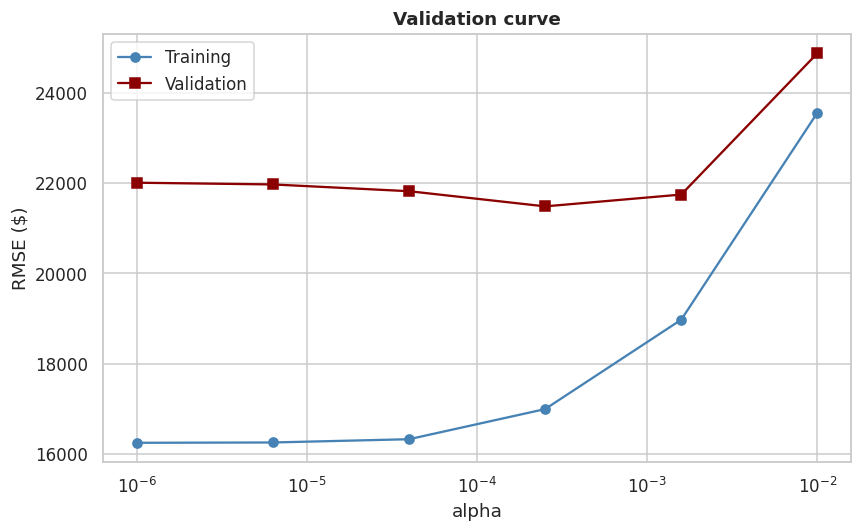

In [22]:
KEY_PARAMETERS = {
    "Ridge": ("regressor__model__alpha", np.logspace(-2, 3, 6), "log"),
    "Lasso": ("regressor__model__alpha", np.logspace(-6, -2, 6), "log"),
    "ElasticNet": ("regressor__model__alpha", np.logspace(-6, -2, 6), "log"),
    "KNN": ("regressor__model__n_neighbors", [3, 5, 7, 9, 12, 15, 21], "linear"),
    "Random Forest": ("regressor__model__max_depth", [4, 6, 8, 10, 12, 16, 20], "linear"),
    "Gradient Boosting": ("regressor__model__max_depth", [2, 3, 4, 5, 6], "linear"),
    "XGBoost": ("regressor__model__max_depth", [2, 3, 4, 5, 6], "linear"),
}

if BEST_MODEL_NAME in KEY_PARAMETERS:
    param_name, param_range, scale = KEY_PARAMETERS[BEST_MODEL_NAME]
    train_scores, valid_scores = validation_curve(
        make_ttr(clone(models[BEST_MODEL_NAME])),
        X_train, y_train,
        param_name=param_name,
        param_range=param_range,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )
    train_rmse, valid_rmse = -train_scores, -valid_scores

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(param_range, train_rmse.mean(axis=1), "o-", label="Training", color="steelblue")
    ax.plot(param_range, valid_rmse.mean(axis=1), "s-", label="Validation", color="darkred")
    if scale == "log":
        ax.set_xscale("log")
    ax.set_xlabel(param_name.replace("regressor__model__", ""))
    ax.set_ylabel("RMSE ($)")
    ax.set_title("Validation curve")
    ax.legend()
    plt.show()

## 11. Final evaluation

The tuned model is evaluated once, on the hold-out set.

In [23]:
final_model = tuned_model
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
final_metrics = regression_metrics(y_test, y_pred)
target_mean = float(y_test.mean())

print(f"FINAL MODEL: {BEST_MODEL_NAME} (tuned)")
print(f"MAE  : ${final_metrics['MAE']:>12,.0f}  ({final_metrics['MAE %']:.2%} of mean price)")
print(f"RMSE : ${final_metrics['RMSE']:>12,.0f}  ({final_metrics['RMSE %']:.2%} of mean price)")
print(f"RMSLE: {final_metrics['RMSLE']:>12.4f}  (Kaggle's metric)")
print(f"R2   : {final_metrics['R2']:>12.4f}  ({final_metrics['R2']:.1%} of variance explained)")
print(f"MAPE : {final_metrics['MAPE']:>12.2%}")


FINAL MODEL: ElasticNet (tuned)
MAE  : $      13,442  (7.41% of mean price)
RMSE : $      18,874  (10.41% of mean price)
RMSLE:       0.1105  (Kaggle's metric)
R2   :       0.9355  (93.6% of variance explained)
MAPE :        8.00%


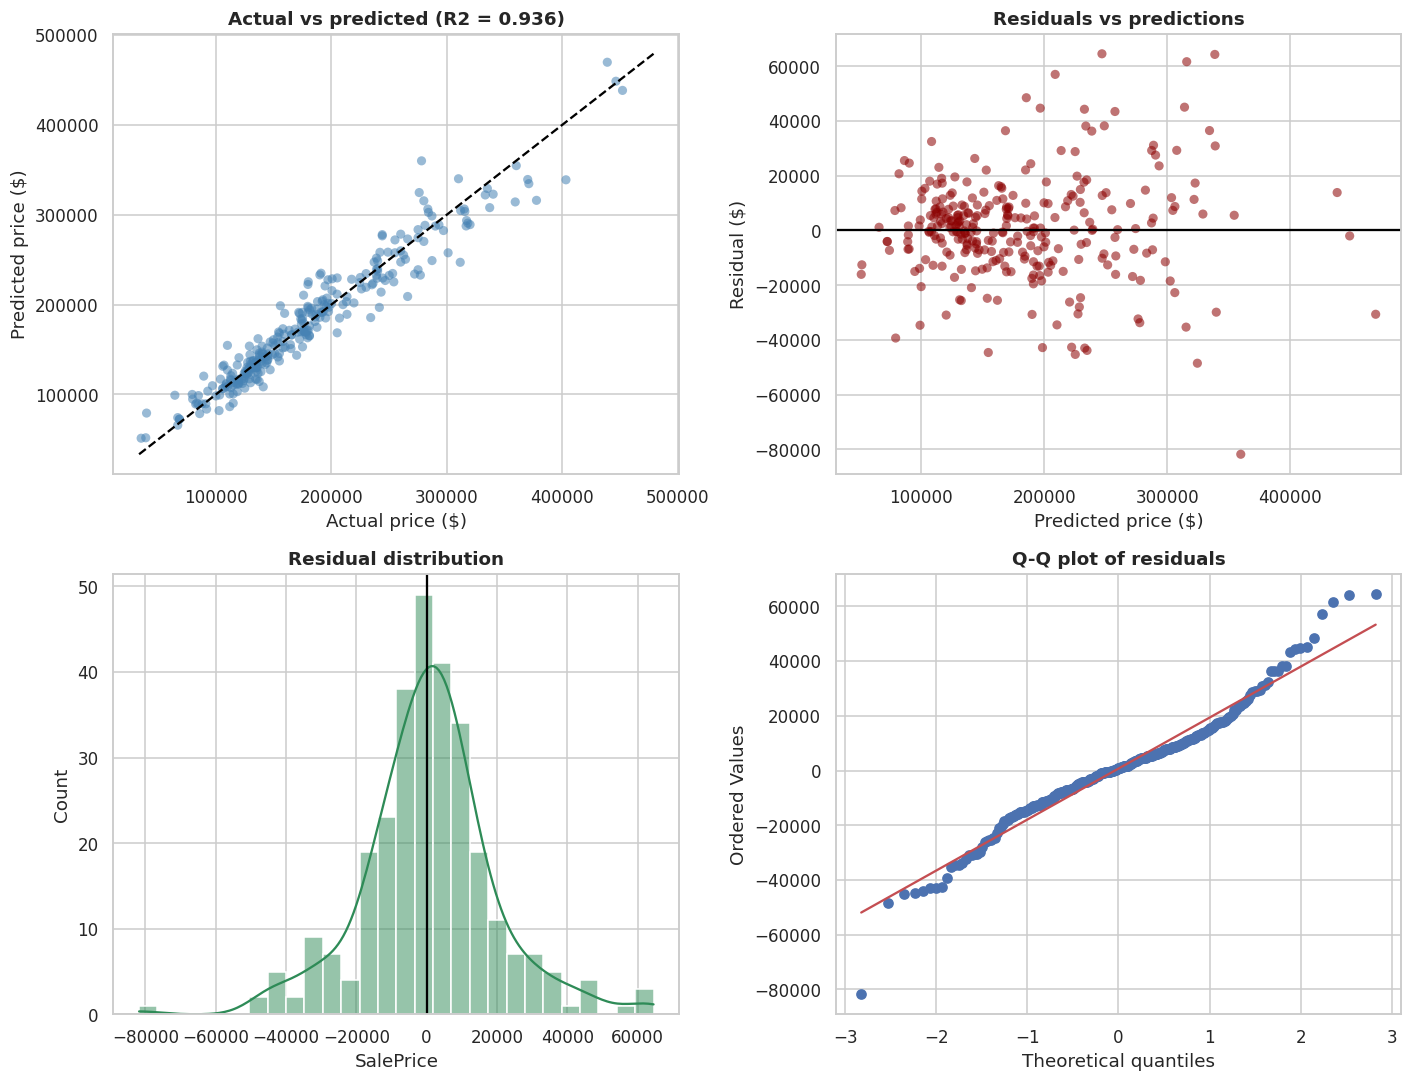

In [24]:
residuals = y_test - y_pred

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].scatter(y_test, y_pred, alpha=0.55, edgecolor="none", color="steelblue")
lims = [min(y_test.min(), y_pred.min()) * 0.95, max(y_test.max(), y_pred.max()) * 1.02]
axes[0, 0].plot(lims, lims, color="black", linestyle="dashed", lw=1.5)
axes[0, 0].set_xlabel("Actual price ($)")
axes[0, 0].set_ylabel("Predicted price ($)")
axes[0, 0].set_title(f"Actual vs predicted (R2 = {final_metrics['R2']:.3f})")

axes[0, 1].scatter(y_pred, residuals, alpha=0.55, edgecolor="none", color="darkred")
axes[0, 1].axhline(0, color="black", lw=1.5)
axes[0, 1].set_xlabel("Predicted price ($)")
axes[0, 1].set_ylabel("Residual ($)")
axes[0, 1].set_title("Residuals vs predictions")

sns.histplot(residuals, kde=True, ax=axes[1, 0], color="seagreen")
axes[1, 0].axvline(0, color="black", lw=1.5)
axes[1, 0].set_title("Residual distribution")

probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot of residuals")
plt.show()

Error by price quintile:


,count,MAE,MAE %
band,,,
Q1 cheapest,60,10814.0,11.0
Q2,57,7652.0,6.0
Q3,60,12183.0,7.0
Q4,56,12474.0,6.0
Q5 priciest,59,23911.0,8.0


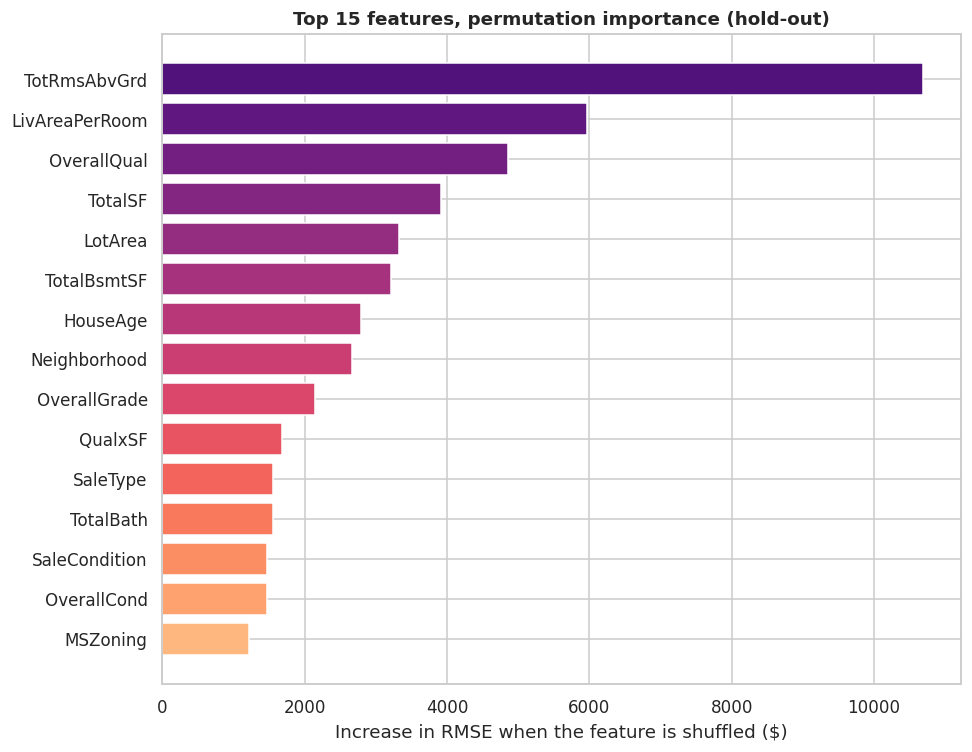

In [25]:
bands = pd.qcut(y_test, q=5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
error_df = pd.DataFrame({
    "actual": y_test, "predicted": y_pred,
    "abs_error": (y_test - y_pred).abs(),
    "band": bands,
})
by_band = error_df.groupby("band", observed=True).agg(
    count=("actual", "size"),
    MAE=("abs_error", "mean"),
    MAE_pct=("abs_error", lambda s: 100 * s.mean() / error_df.loc[s.index, "actual"].mean()),
)
by_band["MAE_pct"] = by_band["MAE_pct"].round(2)
by_band = by_band.rename(columns={"MAE_pct": "MAE %"})
print("Error by price quintile:")
display(by_band.round(0))

perm = permutation_importance(
    final_model, X_test, y_test,
    n_repeats=10,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = (pd.Series(perm.importances_mean, index=X_test.columns)
              .sort_values(ascending=False))

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color=plt.cm.magma(np.linspace(0.85, 0.25, len(top))))
ax.set_title("Top 15 features, permutation importance (hold-out)")
ax.set_xlabel("Increase in RMSE when the feature is shuffled ($)")
plt.show()

 train_size  train_RMSE  train_RMSE_std  val_RMSE  val_RMSE_std  train_RMSE %  val_RMSE %
        155      8067.0          1227.0   31982.0        3033.0        0.0446      0.1768
        310     13284.0          1026.0   23920.0        1680.0        0.0734      0.1322
        466     14055.0           671.0   22958.0        1547.0        0.0777      0.1269
        621     15272.0           534.0   22424.0         750.0        0.0844      0.1239
        777     16782.0           467.0   21280.0        1052.0        0.0928      0.1176
Saved training_history.csv


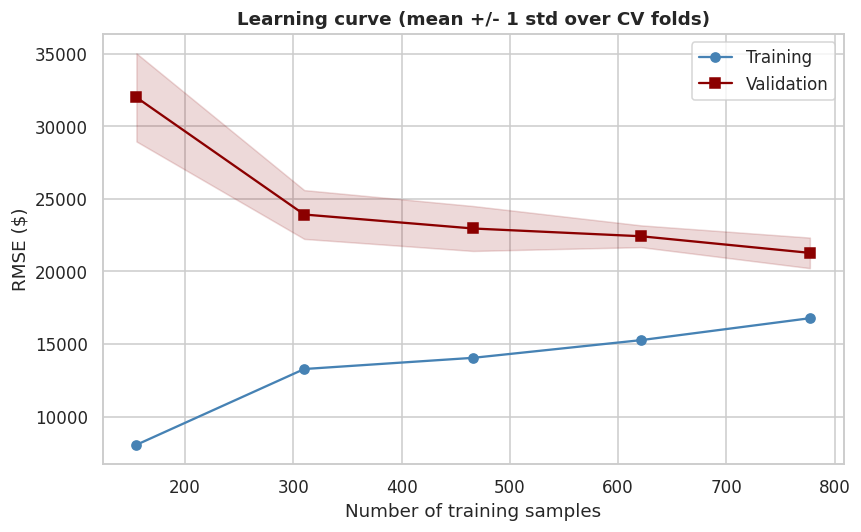

In [26]:
train_sizes, train_scores, valid_scores = learning_curve(
    final_model, X_train, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=3,
    scoring="neg_root_mean_squared_error",
    shuffle=True,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
train_rmse, valid_rmse = -train_scores, -valid_scores

history = pd.DataFrame({
    "train_size": train_sizes,
    "train_RMSE": train_rmse.mean(axis=1),
    "train_RMSE_std": train_rmse.std(axis=1),
    "val_RMSE": valid_rmse.mean(axis=1),
    "val_RMSE_std": valid_rmse.std(axis=1),
})
history["train_RMSE %"] = history["train_RMSE"] / y.mean()
history["val_RMSE %"] = history["val_RMSE"] / y.mean()
history.to_csv("training_history.csv", index=False)
print(history.round({"train_size": 0, "train_RMSE": 0, "train_RMSE_std": 0,
                     "val_RMSE": 0, "val_RMSE_std": 0,
                     "train_RMSE %": 4, "val_RMSE %": 4}).to_string(index=False))
print("Saved training_history.csv")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_sizes, train_rmse.mean(axis=1), "o-", color="steelblue", label="Training")
ax.plot(train_sizes, valid_rmse.mean(axis=1), "s-", color="darkred", label="Validation")
ax.fill_between(train_sizes,
                valid_rmse.mean(axis=1) - valid_rmse.std(axis=1),
                valid_rmse.mean(axis=1) + valid_rmse.std(axis=1),
                color="darkred", alpha=0.15)
ax.set_xlabel("Number of training samples")
ax.set_ylabel("RMSE ($)")
ax.set_title("Learning curve (mean +/- 1 std over CV folds)")
ax.legend()
plt.show()


## 12. Bonus, stacking ensemble

Ridge + Random Forest + Gradient Boosting as base learners, Ridge as meta-learner. Out-of-fold predictions train the meta-learner (no leakage).

In [27]:
base_estimators = [
    ("ridge", Pipeline([
        ("prep", build_preprocessor(NUM_FEATURES, CAT_FEATURES)),
        ("model", Ridge(alpha=10.0)),
    ])),
    ("rf", Pipeline([
        ("prep", build_preprocessor(NUM_FEATURES, CAT_FEATURES)),
        ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    ])),
    ("gb", Pipeline([
        ("prep", build_preprocessor(NUM_FEATURES, CAT_FEATURES)),
        ("model", GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                            max_depth=3, random_state=RANDOM_STATE)),
    ])),
]

stack_model = wrap_target(StackingRegressor(
    estimators=base_estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=1,
))

stack_cv = cross_validate(stack_model, X_train, y_train, cv=cv,
                          scoring={"RMSE": "neg_root_mean_squared_error",
                                   "R2": "r2"},
                          n_jobs=1)
stack_model.fit(X_train, y_train)
stack_holdout = regression_metrics(y_test, stack_model.predict(X_test))

print(f"Stacking 5-fold CV RMSE : ${-stack_cv['test_RMSE'].mean():,.0f}")
print(f"Stacking hold-out RMSE  : ${stack_holdout['RMSE']:,.0f}")
print(f"Stacking hold-out R2    : {stack_holdout['R2']:.4f}")

comparison = pd.DataFrame([
    {"Model": f"{BEST_MODEL_NAME} (tuned)",
     "CV RMSE": -search.best_score_ if search is not None else results.loc[BEST_MODEL_NAME, "CV RMSE"],
     "Hold-out RMSE": final_metrics["RMSE"],
     "Hold-out MAE": final_metrics["MAE"],
     "Hold-out R2": final_metrics["R2"]},
    {"Model": "Stacking (Ridge + RF + GB)",
     "CV RMSE": -stack_cv["test_RMSE"].mean(),
     "Hold-out RMSE": stack_holdout["RMSE"],
     "Hold-out MAE": stack_holdout["MAE"],
     "Hold-out R2": stack_holdout["R2"]},
    {"Model": "Linear Regression (baseline)",
     "CV RMSE": results.loc["Linear Regression", "CV RMSE"],
     "Hold-out RMSE": results.loc["Linear Regression", "Hold-out RMSE"],
     "Hold-out MAE": results.loc["Linear Regression", "Hold-out MAE"],
     "Hold-out R2": results.loc["Linear Regression", "Hold-out R2"]},
]).set_index("Model")
display(comparison.round(3))

Stacking 5-fold CV RMSE : $21,589
Stacking hold-out RMSE  : $18,699
Stacking hold-out R2    : 0.9367


,CV RMSE,Hold-out RMSE,Hold-out MAE,Hold-out R2
Model,,,,
ElasticNet (tuned),21482.367,18873.939,13442.408,0.936
Stacking (Ridge + RF + GB),21589.120,18699.203,13190.412,0.937
Linear Regression (baseline),21965.922,20818.825,14365.240,0.922


## 13. Submission file

`submission.csv` is written next to the notebook (on Kaggle, it appears in the Output tab, ready to upload to the competition). The hold-out evaluation above uses the model fitted on 80% of the data; for the submission the tuned model is **refit on all 1,458 labelled rows** so the leaderboard prediction uses every byte of information available. `holdout_predictions.csv` and `results.json` are also saved for the report and the Streamlit app.

In [28]:
import json

holdout_predictions = pd.DataFrame({
    "row_id": y_test.index,
    "actual": y_test.values,
    "predicted": y_pred,
    "residual": residuals.values,
})
holdout_predictions.to_csv("holdout_predictions.csv", index=False)

# Refit the tuned model on ALL labelled rows for the submission
X_all = log_transform(X.copy(), SKEWED_FEATURES)
submission_model = clone(final_model).fit(X_all, y)
print(f"Submission model refit on all labelled data: {X_all.shape[0]} rows")

X_kaggle = engineer_features(fill_semantic_na(df_test_raw))
X_kaggle = log_transform(X_kaggle, SKEWED_FEATURES)
X_kaggle = X_kaggle[X_train.columns]

submission = pd.DataFrame({
    "Id": df_test_raw["Id"],
    "SalePrice": np.clip(submission_model.predict(X_kaggle), 0, None),
})
submission.to_csv("submission.csv", index=False)
print(f"Saved submission.csv ({len(submission)} rows) and holdout_predictions.csv")
display(submission.head())

# Export everything the Streamlit app needs
full_mean = float(y.mean())
export_models = results.reset_index().round(4).copy()
export_models["CV RMSE %"] = export_models["CV RMSE"] / full_mean
export_models["Hold-out RMSE %"] = export_models["Hold-out RMSE"] / full_mean
export_models["Hold-out MAE %"] = export_models["Hold-out MAE"] / full_mean

results_export = {
    "models": export_models.to_dict(orient="records"),
    "best_model": BEST_MODEL_NAME,
    "tuned_cv_rmse": float(-search.best_score_) if search is not None else None,
    "tuned_params": {
        k.replace("regressor__model__", ""): (float(v) if isinstance(v, (int, float, np.floating)) else str(v))
        for k, v in (search.best_params_.items() if search is not None else [])
    },
    "final_metrics": {k: float(v) for k, v in final_metrics.items()},
    "stacking": {
        "cv_rmse": float(-stack_cv["test_RMSE"].mean()),
        "holdout_rmse": float(stack_holdout["RMSE"]),
        "holdout_mae": float(stack_holdout["MAE"]),
        "holdout_r2": float(stack_holdout["R2"]),
    },
    "target_mean": float(y.mean()),
    "target_median": float(y.median()),
    "target_skew": float(y.skew()),
    "train_rows": int(len(df_model)),
    "test_rows": int(df_test_raw.shape[0]),
    "n_features": int(X_train.shape[1]),
}
with open("results.json", "w", encoding="utf-8") as fh:
    json.dump(results_export, fh, indent=2)
print("Saved results.json")

import sklearn
history_log = {
    "library_versions": {"pandas": pd.__version__, "numpy": np.__version__,
                         "scikit-learn": sklearn.__version__},
    "target_mean": float(y.mean()),
    "train_rows_used_for_cv": int(X_train.shape[0]),
    "train_rows_used_for_submission": int(X_all.shape[0]),
    "model_cv_results": export_models.to_dict(orient="records"),
    "tuning": {
        "best_params": {k.replace("regressor__model__", ""): (float(v) if isinstance(v, (int, float, np.floating)) else str(v))
                        for k, v in (search.best_params_.items() if search is not None else {})},
        "best_cv_rmse": float(-search.best_score_) if search is not None else None,
        "best_cv_rmse_pct": float(-search.best_score_ / full_mean) if search is not None else None,
        "cv_results": {k: (v.tolist() if hasattr(v, "tolist") else v)
                       for k, v in (search.cv_results_.items() if search is not None else {})},
    },
    "learning_curve": history.to_dict(orient="records"),
    "stacking": results_export["stacking"],
    "final_metrics": results_export["final_metrics"],
}
with open("training_history.json", "w", encoding="utf-8") as fh:
    json.dump(history_log, fh, indent=2, default=str)
print("Saved training_history.json (CV of all models, tuning search, train/val curve)")


Submission model refit on all labelled data: 1458 rows
Saved submission.csv (1459 rows) and holdout_predictions.csv


,Id,SalePrice
0,1461,118329.604216
1,1462,152986.726343
2,1463,181479.134940
3,1464,195678.505566
4,1465,200963.848813


Saved results.json
Saved training_history.json (CV of all models, tuning search, train/val curve)


## 14. Bonus, Streamlit web app

Streamlit cannot run inside a Kaggle notebook, so the app is generated as a file: `app.py`. The app is a complete showcase of this work, with five pages in the sidebar:

- **Overview** — dataset summary and EDA highlights (price distribution, price by overall quality)
- **Model comparison** — cross-validated and hold-out metrics of every model trained
- **Final model evaluation** — hold-out metrics, actual vs predicted, residuals, error by price quintile
- **Price predictor** — enter the 16 main characteristics of a house; the app fills the remaining features with typical-house values and scores the request with the **full tuned model**
- **Submission** — preview and statistics of `submission.csv`

Locally, run `pip install streamlit matplotlib joblib` then `streamlit run app.py`. On Kaggle, download `app.py`, `house_price_model.joblib`, `app_meta.json`, `results.json`, `holdout_predictions.csv` and `submission.csv` into one folder and run the same command.

In [29]:
import joblib
import json

# Deploy the FULL tuned submission model. The app asks for the 16 main
# characteristics of a house and fills the remaining raw features with
# typical-house values from the training data (median for numeric, mode otherwise).
OVERRIDABLE_FEATURES = [
    "OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "GarageArea",
    "YearBuilt", "YearRemodAdd", "FullBath", "TotRmsAbvGrd", "FireplaceQu",
    "LotArea", "Neighborhood", "KitchenQual", "ExterQual", "BsmtQual", "CentralAir",
]

raw = df_raw.drop(columns=["Id"])
template = {}
for col in raw.columns:
    s = raw[col]
    if pd.api.types.is_numeric_dtype(s):
        med = float(s.median())
        template[col] = int(med) if med.is_integer() else med
    else:
        template[col] = str(s.mode(dropna=True).iloc[0])

joblib.dump(submission_model, "house_price_model.joblib")

app_meta = {
    "neighborhoods": sorted(df_raw["Neighborhood"].dropna().unique().tolist()),
    "qualities": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "year_min": int(df_raw["YearBuilt"].min()),
    "year_max": int(df_raw["YrSold"].max()),
    "holdout_mae": float(final_metrics["MAE"]),
    "holdout_rmse": float(final_metrics["RMSE"]),
    "holdout_r2": float(final_metrics["R2"]),
    "template": template,
    "skewed_features": SKEWED_FEATURES,
    "feature_columns": X_train.columns.tolist(),
    "overridable_features": OVERRIDABLE_FEATURES,
}
with open("app_meta.json", "w", encoding="utf-8") as fh:
    json.dump(app_meta, fh, indent=2, default=str)

print("Saved house_price_model.joblib (FULL tuned model, refit on all labelled rows)")
print("Saved app_meta.json (typical-house template for the remaining features)")
print(f"App hold-out reference: MAE ${final_metrics['MAE']:,.0f} | RMSE ${final_metrics['RMSE']:,.0f} | R2 {final_metrics['R2']:.4f}")


Saved house_price_model.joblib (FULL tuned model, refit on all labelled rows)
Saved app_meta.json (typical-house template for the remaining features)
App hold-out reference: MAE $13,442 | RMSE $18,874 | R2 0.9355


In [30]:
app_code = r'''
# Streamlit app, House Price Predictor and results showcase.
# Run with: streamlit run app.py
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

BASE = Path(__file__).parent

st.set_page_config(page_title="House Price Predictor", layout="wide")

# ---------- custom transformer (must match the training notebook, or joblib.load fails) ----------
from sklearn.base import BaseEstimator, TransformerMixin

class LotFrontageImputer(BaseEstimator, TransformerMixin):
    def __init__(self, col="LotFrontage", group_col="Neighborhood"):
        self.col = col
        self.group_col = group_col

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        if self.col in X.columns and self.group_col in X.columns:
            self.global_median_ = X[self.col].median()
            self.group_medians_ = X.groupby(self.group_col)[self.col].median()
        else:
            self.global_median_ = None
            self.group_medians_ = None
        return self

    def transform(self, X):
        X = X.copy()
        if self.col in X.columns and self.group_medians_ is not None:
            fill_values = X[self.group_col].map(self.group_medians_).fillna(self.global_median_)
            X[self.col] = X[self.col].fillna(fill_values)
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = getattr(self, "feature_names_in_", None)
        return np.asarray(input_features, dtype=object)

# ---------- feature engineering (same logic as the training notebook) ----------

NA_MEANS_NONE = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]
NA_MEANS_ZERO = [
    "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath",
]

def fill_semantic_na(dataframe):
    df = dataframe.copy()
    for col in NA_MEANS_NONE:
        if col in df.columns:
            df[col] = df[col].fillna("None")
    for col in NA_MEANS_ZERO:
        if col in df.columns:
            df[col] = df[col].fillna(0)
    return df

QUALITY = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

ORDINAL_MAPS = {
    "ExterQual": QUALITY, "ExterCond": QUALITY, "BsmtQual": QUALITY,
    "BsmtCond": QUALITY, "HeatingQC": QUALITY, "KitchenQual": QUALITY,
    "FireplaceQu": QUALITY, "GarageQual": QUALITY, "GarageCond": QUALITY,
    "PoolQC": QUALITY,
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3,
                   "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "CentralAir": {"N": 0, "Y": 1},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "LandSlope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "LotShape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Street": {"Grvl": 0, "Pave": 1},
    "Alley": {"None": 0, "Grvl": 1, "Pave": 2},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
}

def engineer_features(dataframe):
    df = dataframe.copy()
    if "MSSubClass" in df.columns:
        df["MSSubClass"] = df["MSSubClass"].astype(str)
    for col, mapping in ORDINAL_MAPS.items():
        if col in df.columns:
            df[col] = df[col].map(mapping)
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalBath"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                       + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])
    df["TotalPorchSF"] = (df["OpenPorchSF"] + df["EnclosedPorch"]
                          + df["3SsnPorch"] + df["ScreenPorch"])
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
    df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    df["HasBasement"] = (df["TotalBsmtSF"] > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
    df["OverallGrade"] = df["OverallQual"] * df["OverallCond"]
    df["QualxSF"] = df["OverallQual"] * df["TotalSF"]
    df["LivAreaPerRoom"] = df["GrLivArea"] / df["TotRmsAbvGrd"].clip(lower=1)
    df["GarageScore"] = df["GarageArea"] * df["GarageCars"]
    df = df.drop(columns=[c for c in ["Id", "Utilities"] if c in df.columns])
    return df

def log_transform(dataframe, columns):
    df = dataframe.copy()
    for col in columns:
        if col in df.columns:
            df[col] = np.log1p(df[col].clip(lower=0))
    return df

# ---------- artifacts ----------

@st.cache_resource
def load_artifacts():
    model = joblib.load(BASE / "house_price_model.joblib")
    meta = json.loads((BASE / "app_meta.json").read_text(encoding="utf-8"))
    results_path = BASE / "results.json"
    results = json.loads(results_path.read_text(encoding="utf-8")) if results_path.exists() else None
    return model, meta, results

model, meta, results = load_artifacts()

def find_csv(name):
    candidates = [
        BASE / name,
        Path("data") / name,
        Path("archive/data") / name,
        Path("/kaggle/input/competitions/house-prices-advanced-regression-techniques") / name,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        matches = sorted(kaggle_input.rglob(name))
        if matches:
            return matches[0]
    return None

def load_csv(name):
    p = BASE / name
    return pd.read_csv(p) if p.exists() else None

def money(v):
    return f"${v:,.0f}"

page = st.sidebar.radio(
    "Navigation",
    ["Overview", "Model comparison", "Final model evaluation", "Price predictor", "Submission"],
)
st.sidebar.markdown("---")
st.sidebar.caption("Tuned ElasticNet on log(SalePrice) | Ames Housing | trained on 1,458 labelled rows, refit on all data for the submission.")

# ================= Overview =================
if page == "Overview":
    st.title("House Prices, Advanced Regression Techniques")
    st.caption("Kaggle competition | Ames, Iowa | 1,460 labelled rows, 79 features | my Practical Work 1 pipeline")

    train_path = find_csv("train.csv")
    if results:
        c1, c2, c3, c4 = st.columns(4)
        c1.metric("Labelled rows", f"{results['train_rows']:,}")
        c2.metric("Features used", f"{results['n_features']}")
        c3.metric("Mean sale price", money(results["target_mean"]))
        c4.metric("Median sale price", money(results["target_median"]))
        st.caption(f"Target is right-skewed (skew = {results['target_skew']:.2f}), so the model trains on log1p(SalePrice) and predictions are converted back.")

    if train_path is not None:
        df_raw = pd.read_csv(train_path)
        left, right = st.columns(2)
        with left:
            fig, ax = plt.subplots(figsize=(6, 4))
            ax.hist(df_raw["SalePrice"], bins=40, color="steelblue", edgecolor="white")
            ax.set_title("Sale price distribution")
            ax.set_xlabel("SalePrice ($)")
            ax.set_ylabel("Count")
            st.pyplot(fig)
            plt.close(fig)
        with right:
            medians = df_raw.groupby("OverallQual")["SalePrice"].median()
            fig, ax = plt.subplots(figsize=(6, 4))
            ax.bar(medians.index.astype(str), medians.values, color="steelblue")
            ax.set_title("Median price by overall quality")
            ax.set_xlabel("OverallQual")
            ax.set_ylabel("Median SalePrice ($)")
            st.pyplot(fig)
            plt.close(fig)
        st.caption("OverallQual is the strongest single predictor (Spearman r = 0.80), followed by TotalSF (0.82 with the engineered feature) and GrLivArea (0.73).")
    else:
        st.info("train.csv not found next to the app; running in artifact-only mode.")

# ================= Model comparison =================
elif page == "Model comparison":
    st.title("Model comparison")
    st.caption("5-fold cross-validation on the training set, hold-out evaluated once at the end. Lower is better for RMSE/MAE.")
    if not results:
        st.warning("results.json not found; run the notebook first.")
    else:
        models_df = pd.DataFrame(results["models"]).sort_values("CV RMSE").reset_index(drop=True)
        show = models_df.copy()
        for col in ["CV RMSE", "CV RMSE std", "CV MAE", "Hold-out RMSE", "Hold-out MAE"]:
            show[col] = show[col].map(money)
        for col in ["CV R2", "Hold-out R2", "Hold-out MAPE"]:
            show[col] = show[col].map(lambda v: f"{v:.3f}" if col != "Hold-out MAPE" else f"{v:.1%}")
        show["Fit time (s)"] = show["Fit time (s)"].map(lambda v: f"{v:.1f}")
        st.dataframe(show, use_container_width=True, hide_index=True)

        fig, ax = plt.subplots(figsize=(9, 4.5))
        ordered = models_df.sort_values("CV RMSE")
        ax.barh(ordered["Model"], ordered["CV RMSE"], color="steelblue")
        ax.invert_yaxis()
        ax.set_xlabel("CV RMSE ($)")
        ax.set_title("Cross-validated RMSE by model")
        st.pyplot(fig)
        plt.close(fig)

        st.subheader("Tuned ElasticNet vs stacking ensemble vs linear baseline")
        base = models_df[models_df["Model"] == "Linear Regression"].iloc[0]
        comparison = pd.DataFrame([
            {"Model": "ElasticNet (tuned, selected by CV)",
             "CV RMSE": money(results["tuned_cv_rmse"]),
             "Hold-out RMSE": money(results["final_metrics"]["RMSE"]),
             "Hold-out MAE": money(results["final_metrics"]["MAE"]),
             "Hold-out R2": f"{results['final_metrics']['R2']:.4f}"},
            {"Model": "Stacking (Ridge + RF + GB)",
             "CV RMSE": money(results["stacking"]["cv_rmse"]),
             "Hold-out RMSE": money(results["stacking"]["holdout_rmse"]),
             "Hold-out MAE": money(results["stacking"]["holdout_mae"]),
             "Hold-out R2": f"{results['stacking']['holdout_r2']:.4f}"},
            {"Model": "Linear Regression (baseline)",
             "CV RMSE": money(base["CV RMSE"]),
             "Hold-out RMSE": money(base["Hold-out RMSE"]),
             "Hold-out MAE": money(base["Hold-out MAE"]),
             "Hold-out R2": f"{base['Hold-out R2']:.4f}"},
        ])
        st.dataframe(comparison, use_container_width=True, hide_index=True)
        st.markdown(
            "- **Why ElasticNet and not the stacking ensemble:** stacking was marginally better on the hold-out "
            "(R2 0.937 vs 0.936), but worse on cross-validation ($21,589 vs $21,482). The difference is far inside "
            "noise, so the simpler, better-CV model was kept.\n"
            "- **Tuned parameters:** " + ", ".join(f"{k} = {v:.4g}" for k, v in results.get("tuned_params", {}).items())
        )

# ================= Final model evaluation =================
elif page == "Final model evaluation":
    st.title("Final model evaluation (hold-out, 292 houses)")
    if results:
        m = results["final_metrics"]
        c1, c2, c3, c4 = st.columns(4)
        c1.metric("MAE", money(m["MAE"]))
        c2.metric("RMSE", money(m["RMSE"]))
        c3.metric("R2", f"{m['R2']:.4f}")
        c4.metric("MAPE", f"{m['MAPE']:.1%}")

    holdout = load_csv("holdout_predictions.csv")
    if holdout is None:
        st.warning("holdout_predictions.csv not found; run the notebook first.")
    else:
        residuals = holdout["actual"] - holdout["predicted"]
        left, right = st.columns(2)
        with left:
            fig, ax = plt.subplots(figsize=(6, 5))
            ax.scatter(holdout["actual"], holdout["predicted"], alpha=0.5, color="steelblue")
            lims = [holdout[["actual", "predicted"]].min().min(), holdout[["actual", "predicted"]].max().max()]
            ax.plot(lims, lims, color="crimson", linestyle="--", linewidth=1)
            ax.set_xlabel("Actual price ($)")
            ax.set_ylabel("Predicted price ($)")
            ax.set_title("Actual vs predicted")
            st.pyplot(fig)
            plt.close(fig)
        with right:
            fig, ax = plt.subplots(figsize=(6, 5))
            ax.hist(residuals, bins=40, color="steelblue", edgecolor="white")
            ax.axvline(0, color="crimson", linestyle="--", linewidth=1)
            ax.set_xlabel("Residual (actual - predicted, $)")
            ax.set_ylabel("Count")
            ax.set_title("Residual distribution")
            st.pyplot(fig)
            plt.close(fig)

        st.subheader("Error by price quintile")
        hp = holdout.copy()
        hp["abs_error"] = (hp["actual"] - hp["predicted"]).abs()
        hp["band"] = pd.qcut(hp["actual"], q=5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
        by_band = hp.groupby("band", observed=True).agg(
            count=("actual", "size"),
            MAE=("abs_error", "mean"),
        ).reset_index()
        col1, col2 = st.columns([1, 2])
        with col1:
            show = by_band.copy()
            show["MAE"] = show["MAE"].map(money)
            st.dataframe(show, hide_index=True, use_container_width=True)
        with col2:
            fig, ax = plt.subplots(figsize=(7, 4))
            ax.bar(by_band["band"], by_band["MAE"], color="steelblue")
            ax.set_ylabel("MAE ($)")
            ax.set_title("The model underpredicts the priciest quintile")
            st.pyplot(fig)
            plt.close(fig)
        st.caption("Residuals are heteroscedastic: error grows in the top quintile. Expected for a linear model on a log-target; a weighted loss would be the next step.")

# ================= Price predictor =================
elif page == "Price predictor":
    st.title("Price predictor")
    st.caption("Enter the main characteristics. The remaining ~63 raw features are filled with typical-house values from the training data, and the full tuned model scores the request.")

    template = meta["template"]
    qualities = meta["qualities"]
    year_min, year_max = meta["year_min"], meta["year_max"]

    with st.form("house_features"):
        left, right = st.columns(2)
        with left:
            overall_qual = st.slider("Overall quality (1 to 10)", 1, 10, int(template["OverallQual"]))
            gr_liv_area = st.number_input("Living area above ground (sq ft)", 300, 6000, int(template["GrLivArea"]), step=50)
            total_bsmt = st.number_input("Basement area (sq ft)", 0, 3000, int(template["TotalBsmtSF"]), step=50)
            garage_cars = st.slider("Garage capacity (cars)", 0, 4, int(template["GarageCars"]))
            garage_area = st.number_input("Garage area (sq ft)", 0, 1500, int(template["GarageArea"]), step=25)
            year_built = st.number_input("Year built", year_min, year_max, int(template["YearBuilt"]))
            year_remod = st.number_input("Year remodelled", year_min, year_max, int(template["YearRemodAdd"]))
            lot_area = st.number_input("Lot area (sq ft)", 1000, 100000, int(template["LotArea"]), step=500)
        with right:
            neighborhood = st.selectbox("Neighborhood", meta["neighborhoods"], index=meta["neighborhoods"].index(template["Neighborhood"]))
            kitchen_qual = st.selectbox("Kitchen quality", qualities, index=qualities.index(template["KitchenQual"]))
            exter_qual = st.selectbox("Exterior quality", qualities, index=qualities.index(template["ExterQual"]))
            bsmt_qual = st.selectbox("Basement quality", qualities, index=qualities.index(template["BsmtQual"]))
            full_bath = st.slider("Full bathrooms", 0, 4, int(template["FullBath"]))
            tot_rms = st.slider("Rooms above ground", 2, 14, int(template["TotRmsAbvGrd"]))
            fireplace = st.selectbox("Fireplace quality", qualities, index=qualities.index(template["FireplaceQu"]))
            central_air = st.selectbox("Central air", ["Y", "N"], index=["Y", "N"].index(template["CentralAir"]))
        submitted = st.form_submit_button("Estimate the price")

    if submitted:
        row = dict(template)
        row.update({
            "OverallQual": overall_qual, "GrLivArea": gr_liv_area, "TotalBsmtSF": total_bsmt,
            "GarageCars": garage_cars, "GarageArea": garage_area,
            "YearBuilt": year_built, "YearRemodAdd": year_remod, "LotArea": lot_area,
            "FullBath": full_bath, "TotRmsAbvGrd": tot_rms,
            "Neighborhood": neighborhood, "KitchenQual": kitchen_qual,
            "ExterQual": exter_qual, "BsmtQual": bsmt_qual,
            "FireplaceQu": fireplace, "CentralAir": central_air,
        })
        x = pd.DataFrame([row])
        x = fill_semantic_na(x)
        x = engineer_features(x)
        x = log_transform(x, meta["skewed_features"])
        x = x[meta["feature_columns"]]
        price = float(model.predict(x)[0])
        st.metric("Estimated sale price", money(price))
        st.caption(f"Typical error on unseen houses: about {money(meta['holdout_mae'])} MAE (R2 = {meta['holdout_r2']:.3f}). Estimate only, not an appraisal.")
        with st.expander("What the app filled in for you"):
            st.json({k: v for k, v in template.items() if k not in row or row[k] == template[k]})

# ================= Submission =================
elif page == "Submission":
    st.title("Kaggle submission")
    st.caption("submission.csv, generated with the tuned model refit on all 1,458 labelled rows.")
    submission = load_csv("submission.csv")
    if submission is None:
        st.warning("submission.csv not found; run the notebook first.")
    else:
        c1, c2, c3, c4 = st.columns(4)
        c1.metric("Rows", f"{len(submission):,}")
        c2.metric("Min", money(submission["SalePrice"].min()))
        c3.metric("Mean", money(submission["SalePrice"].mean()))
        c4.metric("Max", money(submission["SalePrice"].max()))
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.hist(submission["SalePrice"], bins=40, color="steelblue", edgecolor="white")
        ax.set_xlabel("Predicted SalePrice ($)")
        ax.set_ylabel("Count")
        ax.set_title("Distribution of predicted prices")
        st.pyplot(fig)
        plt.close(fig)
        st.dataframe(submission.head(25), hide_index=True, use_container_width=True)
    st.download_button(
        "Download submission.csv",
        submission.to_csv(index=False).encode("utf-8"),
        file_name="submission.csv",
        mime="text/csv",
        use_container_width=True,
    )

    st.divider()
    st.subheader("Add a submission CSV")
    st.caption("Upload a submission-style CSV (Id, SalePrice) — e.g. sample_submission.csv or a file from another run — to validate it, compare it with the current submission.csv, and download a clean copy for the Kaggle upload.")

    upload = st.file_uploader("Choose a CSV file", type=["csv"], key="submission_upload")
    if upload is None:
        st.info("Nothing uploaded yet. The current submission.csv is shown above.")
    else:
        try:
            up = pd.read_csv(upload)
        except Exception as exc:
            st.error(f"Could not read the file: {exc}")
            up = None
        if up is not None and ("Id" not in up.columns or "SalePrice" not in up.columns):
            st.error(f"The file must contain 'Id' and 'SalePrice' columns; found: {list(up.columns)}")
            up = None
        if up is not None:
            c1, c2, c3, c4 = st.columns(4)
            c1.metric("Rows", f"{len(up):,}")
            c2.metric("NaN prices", int(up["SalePrice"].isna().sum()))
            c3.metric("Price range", f"${up['SalePrice'].min():,.0f} – ${up['SalePrice'].max():,.0f}")
            c4.metric("Duplicate Ids", int(up["Id"].duplicated().sum()))

            checks = [
                ("1459 rows (test set size)", len(up) == 1459),
                ("No missing SalePrice", int(up["SalePrice"].isna().sum()) == 0),
                ("No negative prices", bool((up["SalePrice"] >= 0).all())),
                ("No duplicate Ids", int(up["Id"].duplicated().sum()) == 0),
            ]
            current = load_csv("submission.csv")
            if current is not None:
                overlap = len(set(up["Id"]).intersection(set(current["Id"])))
                checks.append((f"Ids match current submission ({overlap}/{len(current)})", overlap == len(current)))
            for label, ok in checks:
                st.write(("✅" if ok else "❌"), label)

            if current is not None and overlap == len(current):
                merged = current.merge(up, on="Id", suffixes=("_notebook", "_uploaded"))
                diff = (merged["SalePrice_notebook"] - merged["SalePrice_uploaded"]).abs()
                corr = merged["SalePrice_notebook"].corr(merged["SalePrice_uploaded"])
                st.caption(
                    f"Compared with current submission.csv over {len(merged)} Ids — "
                    f"correlation: {corr:.4f}, mean |difference|: {money(diff.mean())}, "
                    f"max |difference|: {money(diff.max())}"
                )
                worst = merged.loc[diff.idxmax(), "Id"]
                st.caption(f"Largest disagreement: Id {int(worst)} — {money(merged.loc[diff.idxmax(), 'SalePrice_notebook'])} vs {money(merged.loc[diff.idxmax(), 'SalePrice_uploaded'])}")
                fig, ax = plt.subplots(figsize=(9, 4))
                ax.hist(current["SalePrice"], bins=40, alpha=0.6, label="current", color="steelblue")
                ax.hist(up["SalePrice"], bins=40, alpha=0.6, label="uploaded", color="darkorange")
                ax.set_xlabel("SalePrice ($)")
                ax.set_ylabel("Count")
                ax.set_title("Predicted price distribution, current vs uploaded")
                ax.legend()
                st.pyplot(fig)
                plt.close(fig)

            st.download_button(
                "Download this submission CSV",
                up.to_csv(index=False).encode("utf-8"),
                file_name="uploaded_submission.csv",
                mime="text/csv",
                use_container_width=True,
            )
'''

with open("app.py", "w", encoding="utf-8") as fh:
    fh.write(app_code)
print(f"Saved app.py ({len(app_code.splitlines())} lines)")


Saved app.py (391 lines)


## 14. Summary

In [31]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Best model          : {BEST_MODEL_NAME} (tuned)")
cv_ref = -search.best_score_ if search is not None else results.loc[BEST_MODEL_NAME, "CV RMSE"]
print(f"Cross-validated RMSE: ${cv_ref:,.0f}  ({cv_ref / y.mean():.2%} of mean price)")
print(f"Hold-out MAE        : ${final_metrics['MAE']:,.0f}  ({final_metrics['MAE %']:.2%} of mean)")
print(f"Hold-out RMSE       : ${final_metrics['RMSE']:,.0f}  ({final_metrics['RMSE %']:.2%} of mean)")
print(f"Hold-out RMSLE      : {final_metrics['RMSLE']:.4f}  (Kaggle's metric)")
print(f"Hold-out R2         : {final_metrics['R2']:.4f}  ({final_metrics['R2']:.1%} of variance explained)")
print(f"Hold-out MAPE       : {final_metrics['MAPE']:.2%}")
print()
print("Model selection note:")
print(f"  Stacking hold-out RMSE ${stack_holdout['RMSE']:,.0f} (R2 {stack_holdout['R2']:.4f}) vs tuned ElasticNet")
print(f"  ${final_metrics['RMSE']:,.0f} (R2 {final_metrics['R2']:.4f}) — an apparent edge that did not hold up")
print(f"  on cross-validation (stacking ${-stack_cv['test_RMSE'].mean():,.0f} vs ElasticNet")
print(f"  ${-search.best_score_ if search is not None else 0:,.0f}). ElasticNet kept on CV grounds.")
print()
print(f"Submission          : submission.csv, tuned model refit on all {X_all.shape[0]} labelled rows")
print("Deployed app        : full tuned model, typical-house template for the features the form does not ask for")
print(f"  app hold-out reference: MAE ${final_metrics['MAE']:,.0f} | RMSE ${final_metrics['RMSE']:,.0f} | R2 {final_metrics['R2']:.4f}")
print("Files written: submission.csv, holdout_predictions.csv, results.json, training_history.csv,")
print("               training_history.json, house_price_model.joblib, app_meta.json, app.py")
print()
print("ON KAGGLE: after 'Run all', download submission.csv here and upload it to the competition.")
print("All files above also appear in the Output tab, ready to download.")


SUMMARY
Best model          : ElasticNet (tuned)
Cross-validated RMSE: $21,482  (11.87% of mean price)
Hold-out MAE        : $13,442  (7.41% of mean)
Hold-out RMSE       : $18,874  (10.41% of mean)
Hold-out RMSLE      : 0.1105  (Kaggle's metric)
Hold-out R2         : 0.9355  (93.6% of variance explained)
Hold-out MAPE       : 8.00%

Model selection note:
  Stacking hold-out RMSE $18,699 (R2 0.9367) vs tuned ElasticNet
  $18,874 (R2 0.9355) — an apparent edge that did not hold up
  on cross-validation (stacking $21,589 vs ElasticNet
  $21,482). ElasticNet kept on CV grounds.

Submission          : submission.csv, tuned model refit on all 1458 labelled rows
Deployed app        : full tuned model, typical-house template for the features the form does not ask for
  app hold-out reference: MAE $13,442 | RMSE $18,874 | R2 0.9355
Files written: submission.csv, holdout_predictions.csv, results.json, training_history.csv,
               training_history.json, house_price_model.joblib, app_meta.